In [1]:
import pandas as pd
import protfasta
import glob
import seaborn as sns
import matplotlib.pyplot as plt
import os
import urllib.parse
import urllib.request
from concurrent.futures import ThreadPoolExecutor, as_completed
import time

# Preparing input script

In [2]:
interpro = pd.read_csv("data/interpro_tf_doms_7-22-25.csv")
interpro["Interpro superfamily domain code"] = interpro["Interpro superfamily domain code"].str.strip().fillna(interpro["Interpro domain code"])
interpro_codes = interpro["Interpro superfamily domain code"].drop_duplicates()
interpro_codes

0     IPR036236
2     IPR009057
3     IPR036638
4     IPR046347
5     IPR036388
6     IPR035500
7     IPR036910
9     IPR036960
10    IPR017956
11    IPR010982
13    IPR038441
14    IPR006600
16    IPR003656
17    IPR013088
18    IPR008967
19    IPR008984
20    IPR010919
21    IPR002857
23    IPR016177
26    IPR036407
28    IPR012345
29    IPR036431
30    IPR057520
31    IPR036879
32    IPR012340
33    IPR013854
34    IPR038096
35    IPR038538
36    IPR038173
38    IPR036647
39    IPR041686
40    IPR006578
41    IPR012295
44    IPR037095
47    IPR000967
49    IPR036115
50    IPR005559
51    IPR033467
52    IPR018586
53    IPR003958
54    IPR007588
Name: Interpro superfamily domain code, dtype: object

In [3]:
len(interpro_codes)

41

In [ ]:
# This is the actual code to download sequences!
# # List of InterPro IDs to fetch
# ipr_ids = interpro_codes #["IPR036236"]  # Replace/add your IPR IDs here

# # Output directory
# os.makedirs("data/interpro_uniprot_downloads/", exist_ok=True)

# # UniProt REST API base
# base_url = "https://rest.uniprot.org/uniprotkb/stream"

# for ipr_id in ipr_ids:
#     # Create UniProt query for existence:1
#     query = f"({ipr_id}) AND (existence:1)Z
#     encoded_query = urllib.parse.quote(query)

#     # Construct URL
#     full_url = f"{base_url}?compressed=true&format=fasta&query={encoded_query}"

#     # Output file path
#     output_file = f"data/interpro_uniprot_downloads/{ipr_id}.fasta.gz"

#     # Download
#     try:
#         print(f"Downloading: {ipr_id}...")
#         urllib.request.urlretrieve(full_url, output_file)
#         print(f"Saved: {output_file}")
#     except Exception as e:
#         print(f"Error downloading {ipr_id}: {e}")

#     time.sleep(1)  # polite delay

In [ ]:
# # Now also getting transcript evidence 

# # List of IPR IDs to query
# ipr_ids = interpro_codes  # Replace or add more

# # Output folder
# os.makedirs("data/interpro_uniprot_downloads/transcript_evidence/", exist_ok=True)

# # Base URL
# base_url = "https://rest.uniprot.org/uniprotkb/stream"

# for ipr_id in ipr_ids:
#     # Construct query: InterPro ID AND existence level 2
#     query = f"({ipr_id}) AND (existence:2)"
#     encoded_query = urllib.parse.quote(query)

#     # Full request URL
#     full_url = f"{base_url}?compressed=true&format=fasta&query={encoded_query}"

#     # Output file path
#     output_file = f"data/interpro_uniprot_downloads/transcript_evidence/{ipr_id}.fasta.gz"

#     # Try downloading
#     try:
#         print(f"Downloading: {ipr_id} (existence:2)...")
#         urllib.request.urlretrieve(full_url, output_file)
#         print(f"Saved to: {output_file}")
#     except Exception as e:
#         print(f"Failed to download {ipr_id}: {e}")

#     #time.sleep(1)  # polite delay

#  ! gunzip data/interpro_uniprot_downloads/transcript_evidence/*


# How many input sequences?

In [4]:
all_dfs = []

for path in glob.glob("data/interpro_uniprot_downloads/IPR*"):
    fasta_dict = protfasta.read_fasta(path, invalid_sequence_action = 'remove')
    path_df = pd.DataFrame({"path" : path, "id" : fasta_dict.keys(), "seq" : fasta_dict.values(), "evidence" : "protein"})
    all_dfs.append(path_df)

for path in glob.glob("data/interpro_uniprot_downloads/transcript_evidence/*"):
    fasta_dict = protfasta.read_fasta(path, invalid_sequence_action = 'remove')
    path_df = pd.DataFrame({"path" : path, "id" : fasta_dict.keys(), "seq" : fasta_dict.values(), "evidence" : "transcript"})
    all_dfs.append(path_df)

all_dfs = pd.concat(all_dfs)
all_dfs["Interpro superfamily domain code"] = all_dfs["path"].str.split("/").str[-1].str.split(".").str[0]
all_dfs

,path,id,seq,evidence,Interpro superfamily domain code
0,data/interpro_uniprot_downloads/IPR036115.fasta,sp|O75603|GCM2_HUMAN Chorion-specific transcri...,MPAAAVQEAVGVCSYGMQLSWDINDPQMPQELALFDQFREWPDGYV...,protein,IPR036115
1,data/interpro_uniprot_downloads/IPR036115.fasta,sp|P70348|GCM1_MOUSE Chorion-specific transcri...,MELDDFDPEDKEILSWDINDVKLPQNVKTTDWFQEWPDSYVKHIYS...,protein,IPR036115
2,data/interpro_uniprot_downloads/IPR036115.fasta,sp|Q27403|GCM_DROME Transcription factor glial...,MVLNGMPITMPVPMPVPMPVPSPPATKSRVAIDWDINDSKMPSVGE...,protein,IPR036115
3,data/interpro_uniprot_downloads/IPR036115.fasta,sp|Q9NP62|GCM1_HUMAN Chorion-specific transcri...,MEPDDFDSEDKEILSWDINDVKLPQNVKKTDWFQEWPDSYAKHIYS...,protein,IPR036115
0,data/interpro_uniprot_downloads/IPR036647.fasta,sp|B7ZQJ9|GT2D1_XENLA General transcription fa...,MALAGKQYEGSLNNSRPNLWPSSIPGGKNEIITSLVTALDSMCTAL...,protein,IPR036647
...,...,...,...,...,...
288,data/interpro_uniprot_downloads/transcript_evi...,tr|W8BT03|W8BT03_CERCA Tigger transposable ele...,MTAKPPKSANKGVKRRNERNILTFYEKIAVIHCYDETSVSRNRLAK...,transcript,IPR006600
289,data/interpro_uniprot_downloads/transcript_evi...,tr|W8BXP4|W8BXP4_CERCA HTH CENPB-type domain-c...,EAAIRESVCSGTEISVKSTSYIRDALKEKMEKALVLSIEDKSQKRM...,transcript,IPR006600
290,data/interpro_uniprot_downloads/transcript_evi...,tr|W8C2P9|W8C2P9_CERCA HTH CENPB-type domain-c...,MELMFPKHRDYKTRNILTMMERVQVIKAYKRMPNYQRLASRFGCSA...,transcript,IPR006600
291,data/interpro_uniprot_downloads/transcript_evi...,tr|W8C8R8|W8C8R8_CERCA Tigger transposable ele...,MDRKRNHCSLSLKQKLEIIKAVADNKHSKNKLAKLYKCNISTINRI...,transcript,IPR006600


In [5]:
# Drop dups 
all_dfs = all_dfs.drop_duplicates(subset = "seq")
all_dfs

,path,id,seq,evidence,Interpro superfamily domain code
0,data/interpro_uniprot_downloads/IPR036115.fasta,sp|O75603|GCM2_HUMAN Chorion-specific transcri...,MPAAAVQEAVGVCSYGMQLSWDINDPQMPQELALFDQFREWPDGYV...,protein,IPR036115
1,data/interpro_uniprot_downloads/IPR036115.fasta,sp|P70348|GCM1_MOUSE Chorion-specific transcri...,MELDDFDPEDKEILSWDINDVKLPQNVKTTDWFQEWPDSYVKHIYS...,protein,IPR036115
2,data/interpro_uniprot_downloads/IPR036115.fasta,sp|Q27403|GCM_DROME Transcription factor glial...,MVLNGMPITMPVPMPVPMPVPSPPATKSRVAIDWDINDSKMPSVGE...,protein,IPR036115
3,data/interpro_uniprot_downloads/IPR036115.fasta,sp|Q9NP62|GCM1_HUMAN Chorion-specific transcri...,MEPDDFDSEDKEILSWDINDVKLPQNVKKTDWFQEWPDSYAKHIYS...,protein,IPR036115
0,data/interpro_uniprot_downloads/IPR036647.fasta,sp|B7ZQJ9|GT2D1_XENLA General transcription fa...,MALAGKQYEGSLNNSRPNLWPSSIPGGKNEIITSLVTALDSMCTAL...,protein,IPR036647
...,...,...,...,...,...
172,data/interpro_uniprot_downloads/transcript_evi...,tr|A0A411G830|A0A411G830_9HYME HTH CENPB-type ...,VRRFIINIDILFSFFDSSFVLYSKMTDSNSNANYQVMDLNSNDVTS...,transcript,IPR006600
177,data/interpro_uniprot_downloads/transcript_evi...,tr|A0A6F9DP70|A0A6F9DP70_9ASCI Uncharacterized...,MEEKATASPKTPGFRKIFSVNEEEIIGKFLISCWKKKLRVPNEVLF...,transcript,IPR006600
179,data/interpro_uniprot_downloads/transcript_evi...,tr|A0A8E6LR96|A0A8E6LR96_9HYPO CENP-B-like pro...,MADSTTDPALVAAEPTDIPSVPAPASASSKERNSLTLDQRRALRRW...,transcript,IPR006600
256,data/interpro_uniprot_downloads/transcript_evi...,tr|T1PL60|T1PL60_MUSDO Regulator of RNA polyme...,MYDELPVYQRVASAFKCSWEQIKNVVANRKQILKYYASCQIIDVMK...,transcript,IPR006600


/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


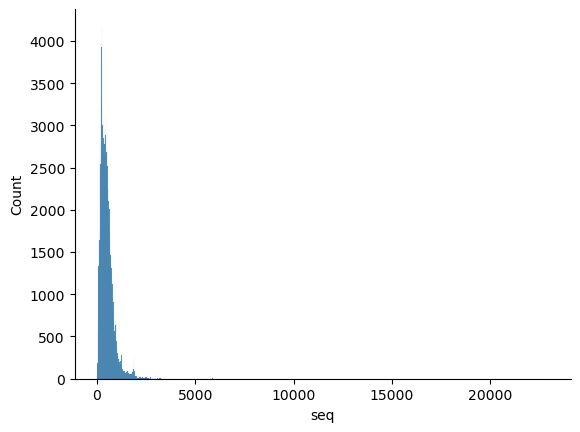

In [6]:
#How are the sequences lengths distributed?
sns.histplot(all_dfs["seq"].str.len())
sns.despine()
# Centered around 450 roughly, most are under1000 seqs

In [7]:
protfasta.write_fasta(dict(zip(all_dfs["id"], all_dfs["seq"])), "data/interpro_uniprot_evid_1_2.fasta")

In [8]:
all_dfs["evidence"].value_counts()

evidence
transcript    78258
protein       59178
Name: count, dtype: int64

In [9]:
# Keep rows with desired codes
seqs_with_codes = pd.merge(all_dfs, interpro, on = "Interpro superfamily domain code")
seqs_with_codes["name"] = seqs_with_codes["id"].str.split("|").str[2]
seqs_with_codes["Interpro domain name shortened"] = seqs_with_codes["Interpro domain name"].str.replace(" domain", "")
seqs_with_codes = seqs_with_codes.drop_duplicates(subset = "seq")
seqs_with_codes

,path,id,seq,evidence,Interpro superfamily domain code,DBD Family,Interpro domain name,Interpro domain code,Interpro superfamily name,name,Interpro domain name shortened
0,data/interpro_uniprot_downloads/IPR036115.fasta,sp|O75603|GCM2_HUMAN Chorion-specific transcri...,MPAAAVQEAVGVCSYGMQLSWDINDPQMPQELALFDQFREWPDGYV...,protein,IPR036115,GCM,Transcription regulator GCM domain,IPR003902,GCM domain superfamily,GCM2_HUMAN Chorion-specific transcription fact...,Transcription regulator GCM
1,data/interpro_uniprot_downloads/IPR036115.fasta,sp|P70348|GCM1_MOUSE Chorion-specific transcri...,MELDDFDPEDKEILSWDINDVKLPQNVKTTDWFQEWPDSYVKHIYS...,protein,IPR036115,GCM,Transcription regulator GCM domain,IPR003902,GCM domain superfamily,GCM1_MOUSE Chorion-specific transcription fact...,Transcription regulator GCM
2,data/interpro_uniprot_downloads/IPR036115.fasta,sp|Q27403|GCM_DROME Transcription factor glial...,MVLNGMPITMPVPMPVPMPVPSPPATKSRVAIDWDINDSKMPSVGE...,protein,IPR036115,GCM,Transcription regulator GCM domain,IPR003902,GCM domain superfamily,GCM_DROME Transcription factor glial cells mis...,Transcription regulator GCM
3,data/interpro_uniprot_downloads/IPR036115.fasta,sp|Q9NP62|GCM1_HUMAN Chorion-specific transcri...,MEPDDFDSEDKEILSWDINDVKLPQNVKKTDWFQEWPDSYAKHIYS...,protein,IPR036115,GCM,Transcription regulator GCM domain,IPR003902,GCM domain superfamily,GCM1_HUMAN Chorion-specific transcription fact...,Transcription regulator GCM
4,data/interpro_uniprot_downloads/transcript_evi...,sp|O09102|GCM2_MOUSE Chorion-specific transcri...,MPADSTQDEDAVLSYGMKLTWDINDPQMPQEPTHFDHFREWPDGYV...,transcript,IPR036115,GCM,Transcription regulator GCM domain,IPR003902,GCM domain superfamily,GCM2_MOUSE Chorion-specific transcription fact...,Transcription regulator GCM
...,...,...,...,...,...,...,...,...,...,...,...
339785,data/interpro_uniprot_downloads/transcript_evi...,tr|W8BGV6|W8BGV6_CERCA Homeobox protein cut-li...,TQSTIVDEIKIKKENHSPLDLDVISQQSAIAAAAAAAAAACANDPN...,transcript,IPR010982,Homeodomain; POU,POU-specific domain,IPR000327,"Lambda repressor-like, DNA-binding domain supe...",W8BGV6_CERCA Homeobox protein cut-like 2 (Frag...,POU-specific
339787,data/interpro_uniprot_downloads/transcript_evi...,tr|W8BNU3|W8BNU3_CERCA Homeobox protein cut (F...,QQQQQQQAHATAAQQHGPSSTTLLSQLVNSTFSSAAPPTTCSSSSS...,transcript,IPR010982,Homeodomain; POU,POU-specific domain,IPR000327,"Lambda repressor-like, DNA-binding domain supe...",W8BNU3_CERCA Homeobox protein cut (Fragment) O...,POU-specific
339789,data/interpro_uniprot_downloads/transcript_evi...,tr|W8BT72|W8BT72_CERCA (Mediterranean fruit fl...,MSDWDTVTVLRKKAPKGSAAKSETVVNHARRQGVPVETTQKYGAGT...,transcript,IPR010982,Homeodomain; POU,POU-specific domain,IPR000327,"Lambda repressor-like, DNA-binding domain supe...",W8BT72_CERCA (Mediterranean fruit fly) hypothe...,POU-specific
339791,data/interpro_uniprot_downloads/transcript_evi...,tr|W8CA59|W8CA59_CERCA Homeobox protein cut (F...,QQQQQQQAHATAAQQHGPSSTTLLSQLVNSTFSSAAPPTTCSSSSS...,transcript,IPR010982,Homeodomain; POU,POU-specific domain,IPR000327,"Lambda repressor-like, DNA-binding domain supe...",W8CA59_CERCA Homeobox protein cut (Fragment) O...,POU-specific


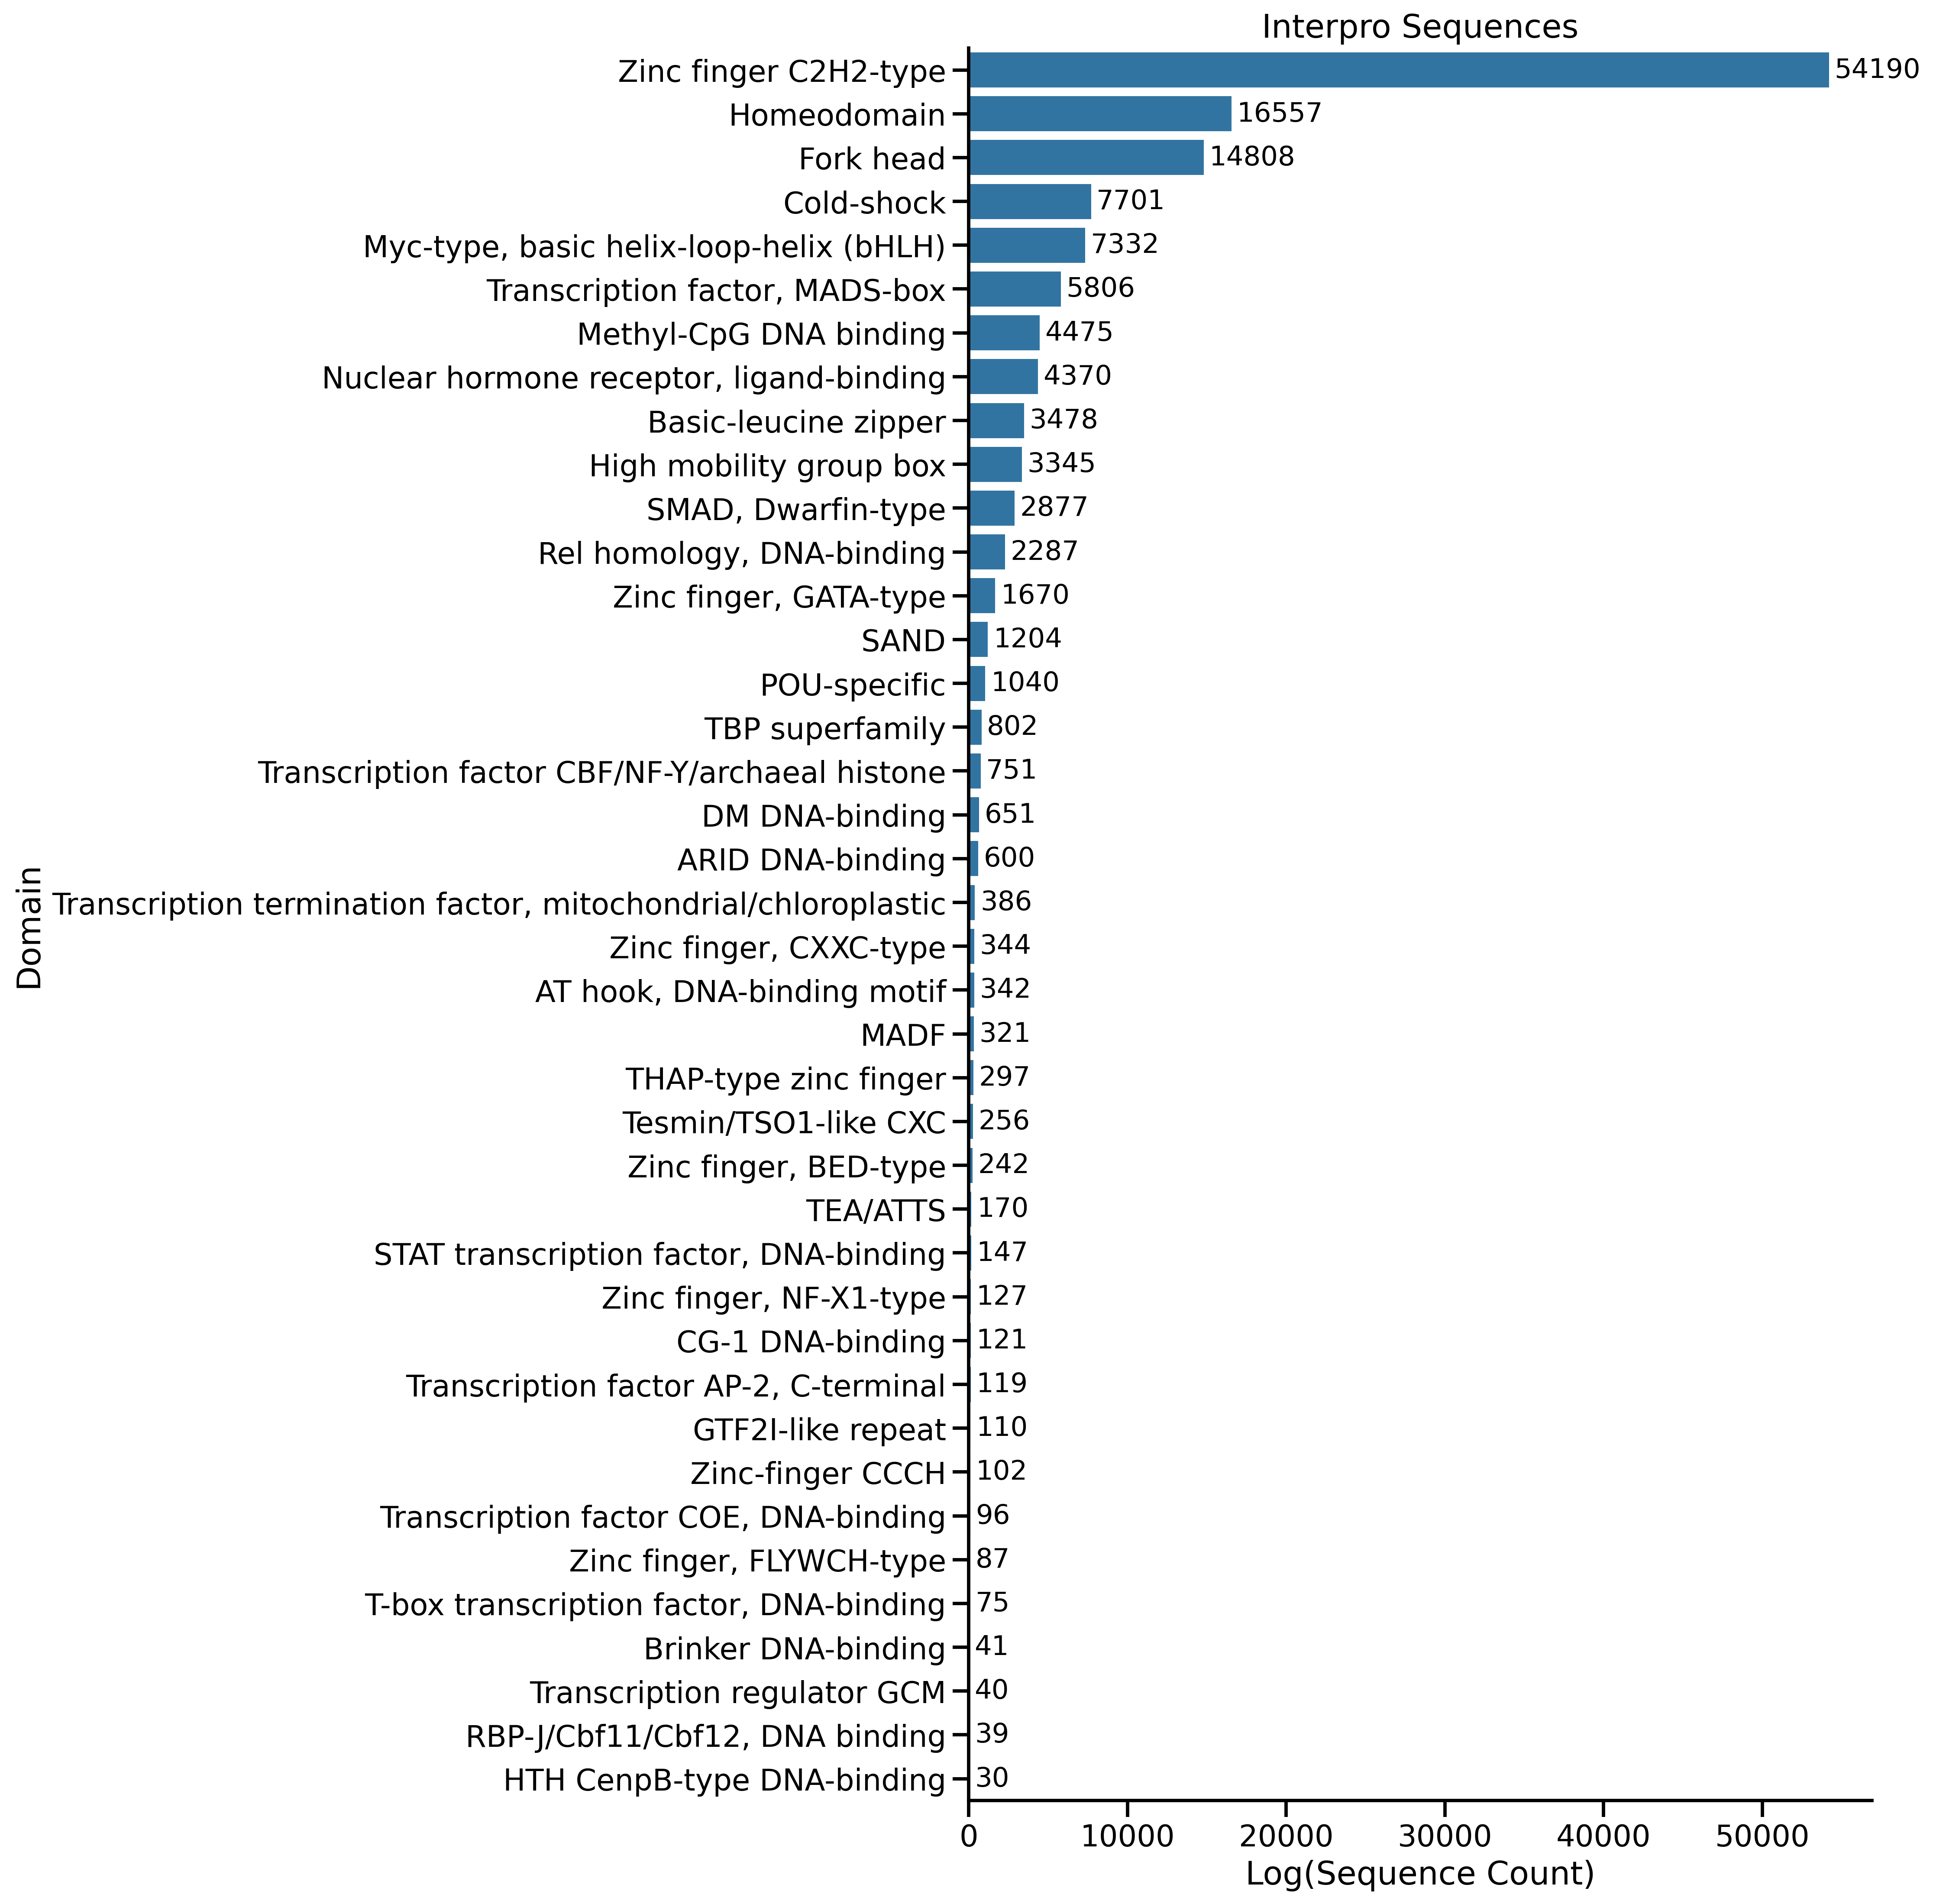

In [10]:
sns.set_context('talk')

counts = seqs_with_codes["Interpro domain name shortened"].value_counts()

plt.figure(figsize=(15, 15), dpi = 300)
ax = sns.barplot(
    y=counts.index,
    x=counts.values,
    color = sns.color_palette('tab10')[0]
)

# Set log scale for x-axis
#ax.set_xscale('log')

# # Remove top and right spines
sns.despine()

# Add labels at the end of each bar
for container in ax.containers:
    ax.bar_label(container, labels=[f"{int(v)}" for v in container.datavalues],
                 label_type='edge', fontsize='small', padding=3)

# Axis labels
plt.xlabel("Log(Sequence Count)")
plt.ylabel("")
plt.title("Interpro Sequences")
plt.ylabel("Domain")

plt.tight_layout()
plt.show()


# What species?

In [13]:
seqs_with_codes["uniprotID"] = seqs_with_codes["id"].str.split("|").str[1]
seqs_with_codes

,path,id,seq,evidence,Interpro superfamily domain code,DBD Family,Interpro domain name,Interpro domain code,Interpro superfamily name,name,Interpro domain name shortened,uniprotID
0,data/interpro_uniprot_downloads/IPR036115.fasta,sp|O75603|GCM2_HUMAN Chorion-specific transcri...,MPAAAVQEAVGVCSYGMQLSWDINDPQMPQELALFDQFREWPDGYV...,protein,IPR036115,GCM,Transcription regulator GCM domain,IPR003902,GCM domain superfamily,GCM2_HUMAN Chorion-specific transcription fact...,Transcription regulator GCM,O75603
1,data/interpro_uniprot_downloads/IPR036115.fasta,sp|P70348|GCM1_MOUSE Chorion-specific transcri...,MELDDFDPEDKEILSWDINDVKLPQNVKTTDWFQEWPDSYVKHIYS...,protein,IPR036115,GCM,Transcription regulator GCM domain,IPR003902,GCM domain superfamily,GCM1_MOUSE Chorion-specific transcription fact...,Transcription regulator GCM,P70348
2,data/interpro_uniprot_downloads/IPR036115.fasta,sp|Q27403|GCM_DROME Transcription factor glial...,MVLNGMPITMPVPMPVPMPVPSPPATKSRVAIDWDINDSKMPSVGE...,protein,IPR036115,GCM,Transcription regulator GCM domain,IPR003902,GCM domain superfamily,GCM_DROME Transcription factor glial cells mis...,Transcription regulator GCM,Q27403
3,data/interpro_uniprot_downloads/IPR036115.fasta,sp|Q9NP62|GCM1_HUMAN Chorion-specific transcri...,MEPDDFDSEDKEILSWDINDVKLPQNVKKTDWFQEWPDSYAKHIYS...,protein,IPR036115,GCM,Transcription regulator GCM domain,IPR003902,GCM domain superfamily,GCM1_HUMAN Chorion-specific transcription fact...,Transcription regulator GCM,Q9NP62
4,data/interpro_uniprot_downloads/transcript_evi...,sp|O09102|GCM2_MOUSE Chorion-specific transcri...,MPADSTQDEDAVLSYGMKLTWDINDPQMPQEPTHFDHFREWPDGYV...,transcript,IPR036115,GCM,Transcription regulator GCM domain,IPR003902,GCM domain superfamily,GCM2_MOUSE Chorion-specific transcription fact...,Transcription regulator GCM,O09102
...,...,...,...,...,...,...,...,...,...,...,...,...
339785,data/interpro_uniprot_downloads/transcript_evi...,tr|W8BGV6|W8BGV6_CERCA Homeobox protein cut-li...,TQSTIVDEIKIKKENHSPLDLDVISQQSAIAAAAAAAAAACANDPN...,transcript,IPR010982,Homeodomain; POU,POU-specific domain,IPR000327,"Lambda repressor-like, DNA-binding domain supe...",W8BGV6_CERCA Homeobox protein cut-like 2 (Frag...,POU-specific,W8BGV6
339787,data/interpro_uniprot_downloads/transcript_evi...,tr|W8BNU3|W8BNU3_CERCA Homeobox protein cut (F...,QQQQQQQAHATAAQQHGPSSTTLLSQLVNSTFSSAAPPTTCSSSSS...,transcript,IPR010982,Homeodomain; POU,POU-specific domain,IPR000327,"Lambda repressor-like, DNA-binding domain supe...",W8BNU3_CERCA Homeobox protein cut (Fragment) O...,POU-specific,W8BNU3
339789,data/interpro_uniprot_downloads/transcript_evi...,tr|W8BT72|W8BT72_CERCA (Mediterranean fruit fl...,MSDWDTVTVLRKKAPKGSAAKSETVVNHARRQGVPVETTQKYGAGT...,transcript,IPR010982,Homeodomain; POU,POU-specific domain,IPR000327,"Lambda repressor-like, DNA-binding domain supe...",W8BT72_CERCA (Mediterranean fruit fly) hypothe...,POU-specific,W8BT72
339791,data/interpro_uniprot_downloads/transcript_evi...,tr|W8CA59|W8CA59_CERCA Homeobox protein cut (F...,QQQQQQQAHATAAQQHGPSSTTLLSQLVNSTFSSAAPPTTCSSSSS...,transcript,IPR010982,Homeodomain; POU,POU-specific domain,IPR000327,"Lambda repressor-like, DNA-binding domain supe...",W8CA59_CERCA Homeobox protein cut (Fragment) O...,POU-specific,W8CA59


In [14]:
seqs_with_codes[["uniprotID"]].to_csv("data/interpro_seq_uniprotids.csv", index = None, header = None)

In [15]:
interpro_species = pd.read_csv("data/interpro_seq_species.txt", sep = "\t")
interpro_species = interpro_species.rename(columns = {"From" : "uniprotID"})
interpro_species = interpro_species.drop(columns = "Entry")
interpro_species

,uniprotID,Organism
0,A0A1L8FFY5,Xenopus laevis (African clawed frog)
1,A1L0Z1,Xenopus tropicalis (Western clawed frog) (Silu...
2,A7Y7W2,Gallus gallus (Chicken)
3,B3DM23,Xenopus tropicalis (Western clawed frog) (Silu...
4,B3DM25,Xenopus tropicalis (Western clawed frog) (Silu...
...,...,...
12779,Q9Y5Q3,Homo sapiens (Human)
12780,Q9Z125,Mus musculus (Mouse)
12781,Q9Z2Q8,Cricetulus griseus (Chinese hamster) (Cricetul...
12782,O82368,Arabidopsis thaliana (Mouse-ear cress)


In [16]:
seqs_with_codes["Organism"] = seqs_with_codes["id"].str.split("OS=").str[1].str.split("OX").str[0]
seqs_with_codes["Organism"].value_counts().head(15)

Organism
Homo sapiens                     6256
Mus musculus                     4554
Zea mays                         3371
Macaca mulatta                   2227
Arabidopsis thaliana             2194
Sus scrofa                       2066
Rattus norvegicus                2029
Danio rerio                      1956
Pan troglodytes                  1751
Callithrix jacchus               1746
Xenopus laevis                   1624
Drosophila melanogaster          1468
Ixodes ricinus                   1424
Gallus gallus                    1286
Oryza sativa subsp. japonica     1236
Name: count, dtype: int64

In [17]:
seqs_with_codes["Organism"].value_counts()

Organism
Homo sapiens                                                                                                           6256
Mus musculus                                                                                                           4554
Zea mays                                                                                                               3371
Macaca mulatta                                                                                                         2227
Arabidopsis thaliana                                                                                                   2194
                                                                                                                       ... 
Lacticaseibacillus paracasei (strain ATCC 334 / BCRC 17002 / CCUG 31169 / CIP 107868 / KCTC 3260 / NRRL B-441)            1
Levilactobacillus brevis (strain ATCC 367 / BCRC 12310 / CIP 105137 / JCM 1170 / LMG 11437 / NCIMB 947 / NCTC 947)        1

In [18]:
seqs_with_codes["Organism"].value_counts()[seqs_with_codes["Organism"].value_counts() > 10]

Organism
Homo sapiens                      6256
Mus musculus                      4554
Zea mays                          3371
Macaca mulatta                    2227
Arabidopsis thaliana              2194
                                  ... 
Aristolochia ringens                11
Lethenteron reissneri               11
Citrus reticulata                   11
Pristina longiseta                  11
Tetracapsuloides bryosalmonae       11
Name: count, Length: 1238, dtype: int64

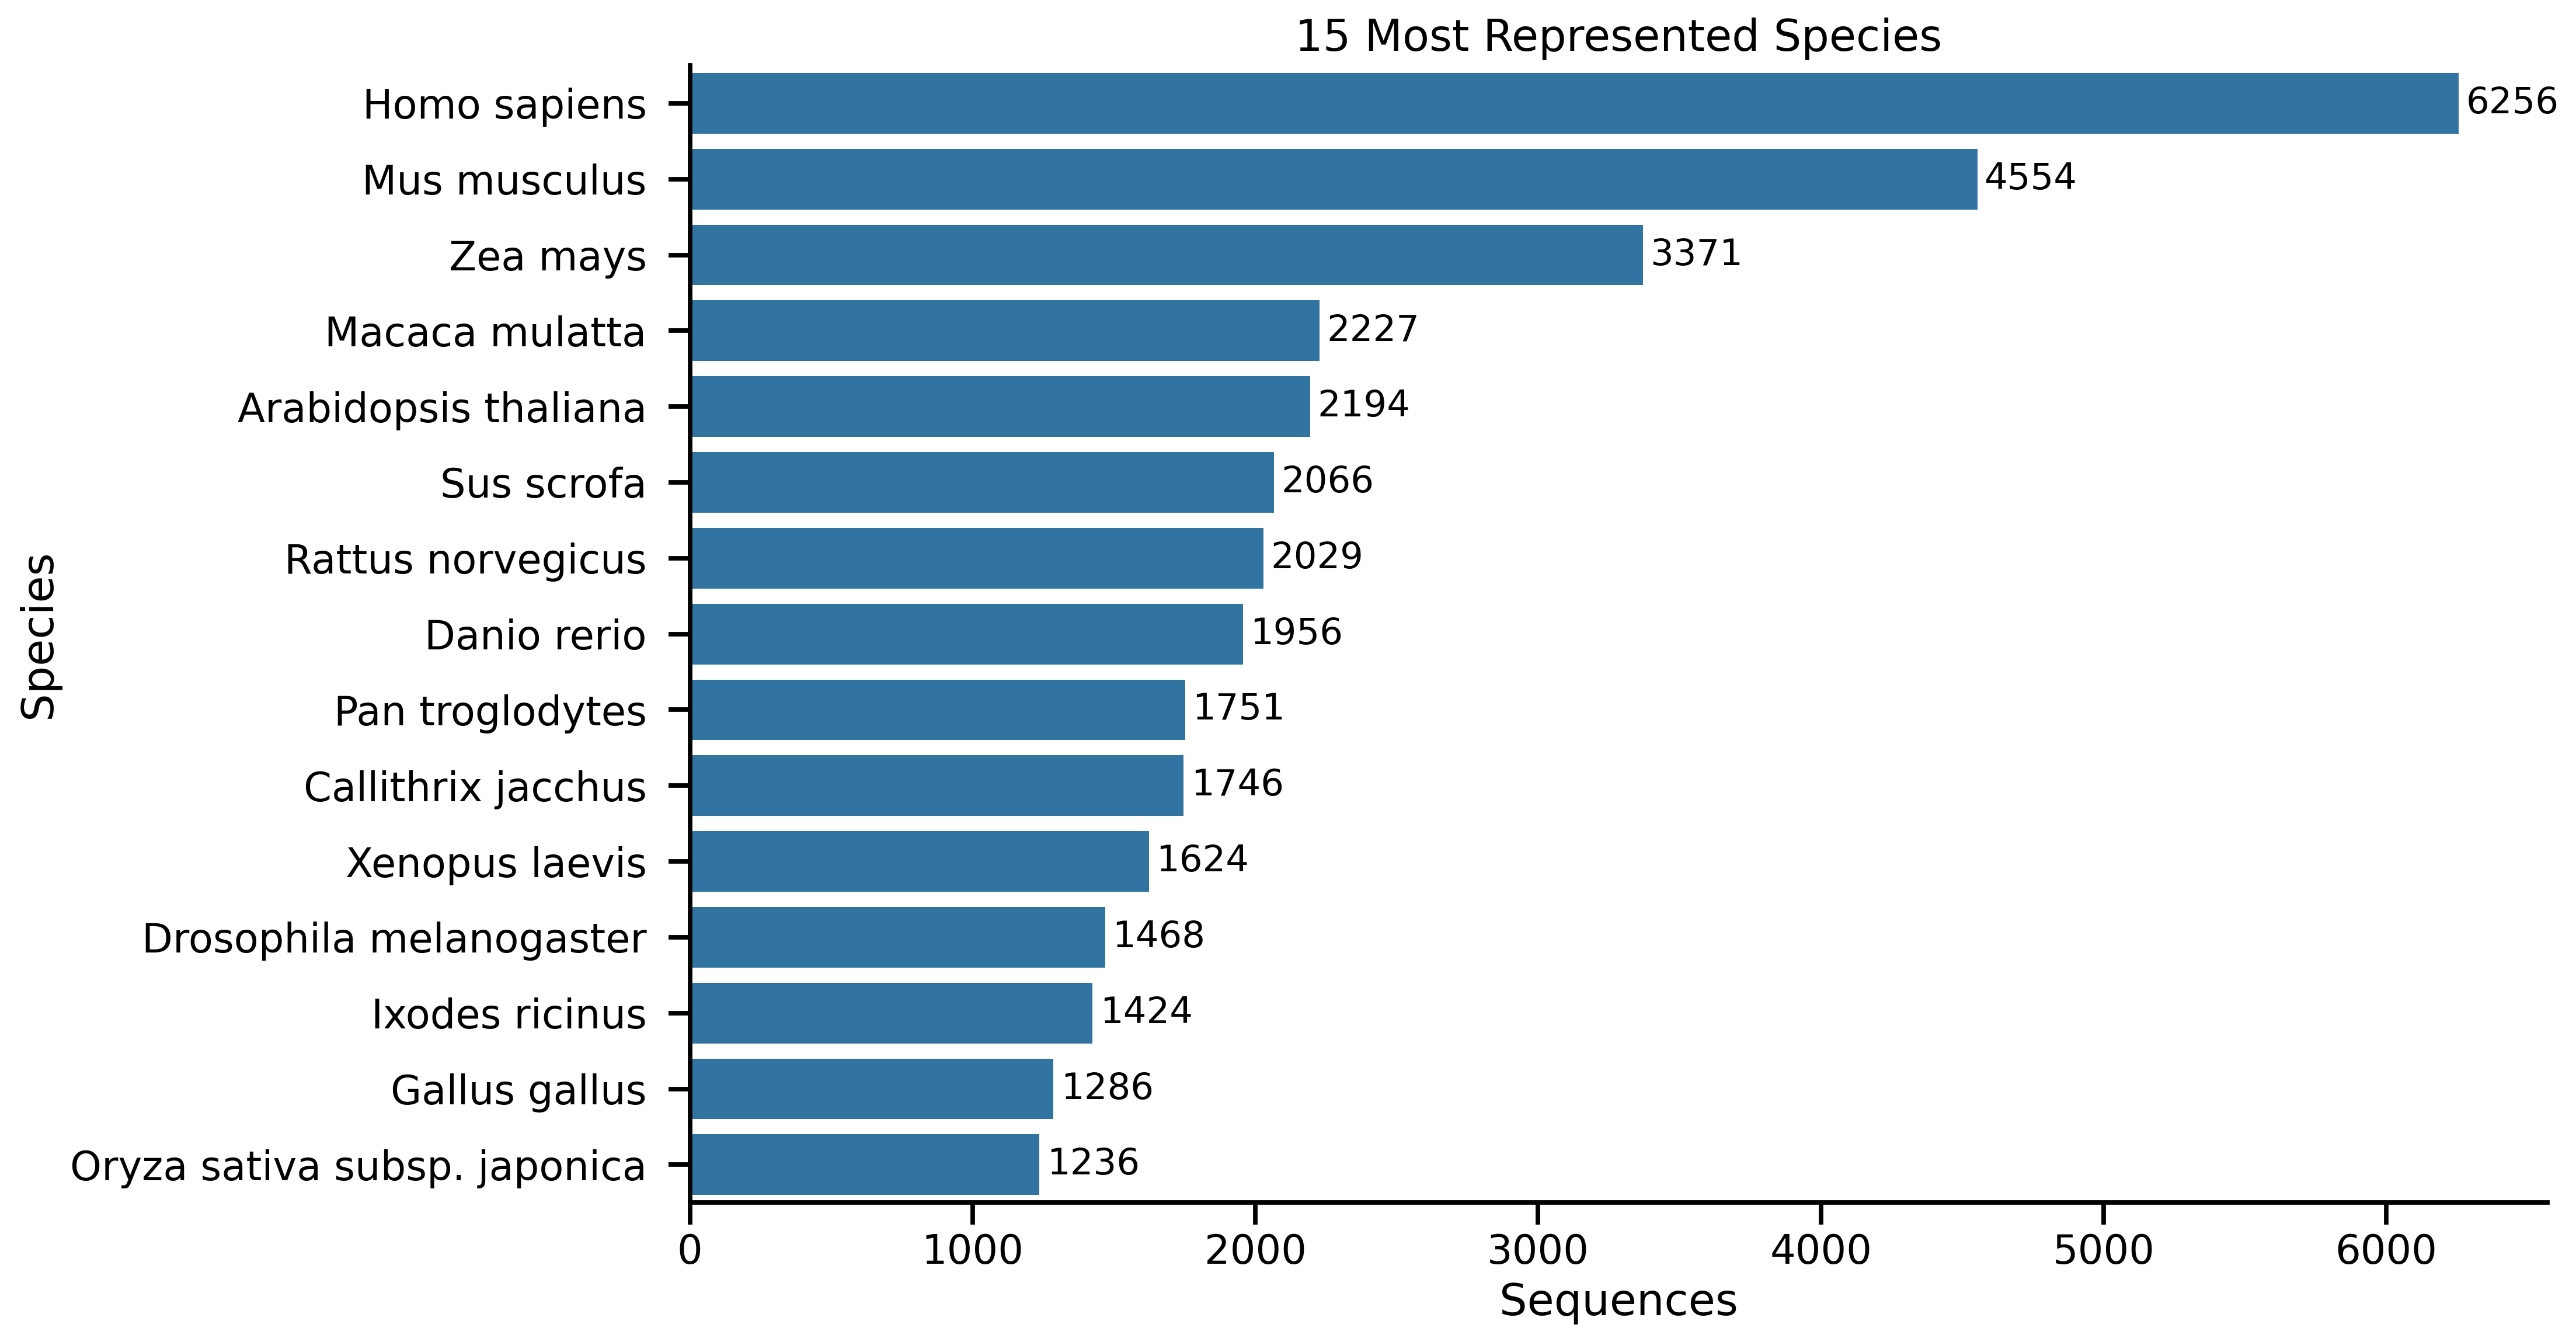

In [19]:
sns.set_context('talk')

counts = seqs_with_codes["Organism"].value_counts().head(15)

plt.figure(figsize=(15, 8), dpi = 300)
ax = sns.barplot(
    y=counts.index,
    x=counts.values, color = sns.color_palette('tab10')[0]
)

# Set log scale for x-axis

# Remove top and right spines
sns.despine()

# Add labels at the end of each bar
for container in ax.containers:
    ax.bar_label(container, labels=[f"{int(v)}" for v in container.datavalues],
                 label_type='edge', fontsize='small', padding=3)

# Axis labels
plt.xlabel("Sequences")
plt.ylabel("")
plt.title("15 Most Represented Species")
plt.ylabel("Species")

plt.tight_layout()
plt.show()
